
# Machine Learning Assignment 2

## Bank Marketing Campaign – Classification

**Programme:** M.Tech AIML

**Subject:** Machine Learning

**Dataset:** Bank Marketing Dataset

**Dataset Source:** UCI Machine Learning Repository

**Objective:** To implement and compare five machine learning classification algorithms to predict whether a bank customer will subscribe to a term deposit.



## 1. Problem Statement

The objective of this project is to develop machine learning classification models to predict whether a customer will subscribe to a bank term deposit based on customer demographic information, marketing campaign details and economic indicators.

The Bank Marketing dataset obtained from the UCI Machine Learning Repository is used for this classification task.

The target variable is 'y':

- Yes: Customer subscribed to a term deposit.
- No: Customer did not subscribe to a term deposit.

### Project Objectives

1. Understand and explore the dataset.
2. Identify and handle missing values and duplicate records.
3. Perform categorical encoding and numerical feature scaling.
4. Divide the dataset into training and testing sets using an 80:20 ratio.
5. Implement five machine learning classification algorithms.
6. Evaluate the models using six performance metrics.
7. Compare model performance and identify the overall winner.


In [2]:
# 2. Import Required Libraries

import pandas as pd
import numpy as np

import matplotlib.pyplot as plt
import seaborn as sns

import warnings
warnings.filterwarnings('ignore')

# Scikit-learn preprocessing and splitting

from sklearn.model_selection import train_test_split
from sklearn.compose import ColumnTransformer
from sklearn.preprocessing import StandardScaler, OneHotEncoder
from sklearn.pipeline import Pipeline

# Classification algorithms

from sklearn.linear_model import LogisticRegression
from sklearn.tree import DecisionTreeClassifier
from sklearn.neighbors import KNeighborsClassifier
from sklearn.naive_bayes import GaussianNB
from sklearn.ensemble import RandomForestClassifier

# Evaluation metrics

from sklearn.metrics import (
    accuracy_score,
    roc_auc_score,
    precision_score,
    recall_score,
    f1_score,
    matthews_corrcoef,
    confusion_matrix,
    classification_report
)

# Saving models

import joblib
import os

# Fixed random seed

RANDOM_STATE = 42

# Visualization settings

sns.set_theme(style="whitegrid")

print("All libraries imported successfully!")

All libraries imported successfully!



## 3. Dataset Loading

The Bank Marketing dataset is obtained from the UCI Machine Learning Repository.

The selected dataset file is bank-additional-full.csv.

It contains 41,188 customer records, 20 independent features and one target variable.

The CSV file uses a semicolon (;) as its separator.


In [3]:
# 3. Load Dataset

from google.colab import files

uploaded = files.upload()

df = pd.read_csv(
    'bank-additional-full.csv',
    sep=';'
)

print("Dataset loaded successfully!")

df.head()

Saving bank-additional-full.csv to bank-additional-full.csv
Dataset loaded successfully!


,age,job,marital,education,default,housing,loan,contact,month,day_of_week,...,campaign,pdays,previous,poutcome,emp.var.rate,cons.price.idx,cons.conf.idx,euribor3m,nr.employed,y
0,56,housemaid,married,basic.4y,no,no,no,telephone,may,mon,...,1,999,0,nonexistent,1.1,93.994,-36.4,4.857,5191.0,no
1,57,services,married,high.school,unknown,no,no,telephone,may,mon,...,1,999,0,nonexistent,1.1,93.994,-36.4,4.857,5191.0,no
2,37,services,married,high.school,no,yes,no,telephone,may,mon,...,1,999,0,nonexistent,1.1,93.994,-36.4,4.857,5191.0,no
3,40,admin.,married,basic.6y,no,no,no,telephone,may,mon,...,1,999,0,nonexistent,1.1,93.994,-36.4,4.857,5191.0,no
4,56,services,married,high.school,no,no,yes,telephone,may,mon,...,1,999,0,nonexistent,1.1,93.994,-36.4,4.857,5191.0,no


In [4]:
# 4. Verify Dataset

print("Number of Rows:", df.shape[0])
print("Number of Columns:", df.shape[1])

print("\nDataset Preview:")
display(df.head())

print("\nDataset loaded successfully!")

Number of Rows: 41188
Number of Columns: 21

Dataset Preview:


,age,job,marital,education,default,housing,loan,contact,month,day_of_week,...,campaign,pdays,previous,poutcome,emp.var.rate,cons.price.idx,cons.conf.idx,euribor3m,nr.employed,y
0,56,housemaid,married,basic.4y,no,no,no,telephone,may,mon,...,1,999,0,nonexistent,1.1,93.994,-36.4,4.857,5191.0,no
1,57,services,married,high.school,unknown,no,no,telephone,may,mon,...,1,999,0,nonexistent,1.1,93.994,-36.4,4.857,5191.0,no
2,37,services,married,high.school,no,yes,no,telephone,may,mon,...,1,999,0,nonexistent,1.1,93.994,-36.4,4.857,5191.0,no
3,40,admin.,married,basic.6y,no,no,no,telephone,may,mon,...,1,999,0,nonexistent,1.1,93.994,-36.4,4.857,5191.0,no
4,56,services,married,high.school,no,no,yes,telephone,may,mon,...,1,999,0,nonexistent,1.1,93.994,-36.4,4.857,5191.0,no



Dataset loaded successfully!


## 4. Dataset Description and Exploration

The Bank Marketing dataset contains customer demographic information, marketing campaign details and economic indicators.

The dataset consists of 41,188 observations and 20 independent features.

The target variable is 'y', which indicates whether a customer subscribed to a term deposit.

This section examines the dataset structure, feature types, statistical summary, missing values, duplicate records and target class distribution.

In [5]:
# 4.1 Dataset Dimensions

print("Dataset Shape:", df.shape)

# 4.2 Column Names

print("\nColumn Names:")
print(df.columns.tolist())

# 4.3 Dataset Information

print("\nDataset Information:")
df.info()

# 4.4 Statistical Summary

print("\nStatistical Summary:")
display(df.describe(include='all'))

# 4.5 Missing Values

print("\nMissing Values:")
print(df.isnull().sum())

# 4.6 Duplicate Records

print("\nDuplicate Records:")
print(df.duplicated().sum())

# 4.7 Target Distribution

print("\nTarget Distribution:")
print(df['y'].value_counts())

# 4.8 Target Percentage

print("\nTarget Percentage:")
print(df['y'].value_counts(normalize=True) * 100)

Dataset Shape: (41188, 21)

Column Names:
['age', 'job', 'marital', 'education', 'default', 'housing', 'loan', 'contact', 'month', 'day_of_week', 'duration', 'campaign', 'pdays', 'previous', 'poutcome', 'emp.var.rate', 'cons.price.idx', 'cons.conf.idx', 'euribor3m', 'nr.employed', 'y']

Dataset Information:
<class 'pandas.core.frame.DataFrame'>
RangeIndex: 41188 entries, 0 to 41187
Data columns (total 21 columns):
 #   Column          Non-Null Count  Dtype  
---  ------          --------------  -----  
 0   age             41188 non-null  int64  
 1   job             41188 non-null  object 
 2   marital         41188 non-null  object 
 3   education       41188 non-null  object 
 4   default         41188 non-null  object 
 5   housing         41188 non-null  object 
 6   loan            41188 non-null  object 
 7   contact         41188 non-null  object 
 8   month           41188 non-null  object 
 9   day_of_week     41188 non-null  object 
 10  duration        41188 non-null  int64

,age,job,marital,education,default,housing,loan,contact,month,day_of_week,...,campaign,pdays,previous,poutcome,emp.var.rate,cons.price.idx,cons.conf.idx,euribor3m,nr.employed,y
count,41188.00000,41188,41188,41188,41188,41188,41188,41188,41188,41188,...,41188.000000,41188.000000,41188.000000,41188,41188.000000,41188.000000,41188.000000,41188.000000,41188.000000,41188
unique,NaN,12,4,8,3,3,3,2,10,5,...,NaN,NaN,NaN,3,NaN,NaN,NaN,NaN,NaN,2
top,NaN,admin.,married,university.degree,no,yes,no,cellular,may,thu,...,NaN,NaN,NaN,nonexistent,NaN,NaN,NaN,NaN,NaN,no
freq,NaN,10422,24928,12168,32588,21576,33950,26144,13769,8623,...,NaN,NaN,NaN,35563,NaN,NaN,NaN,NaN,NaN,36548
mean,40.02406,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,...,2.567593,962.475454,0.172963,NaN,0.081886,93.575664,-40.502600,3.621291,5167.035911,NaN
std,10.42125,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,...,2.770014,186.910907,0.494901,NaN,1.570960,0.578840,4.628198,1.734447,72.251528,NaN
min,17.00000,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,...,1.000000,0.000000,0.000000,NaN,-3.400000,92.201000,-50.800000,0.634000,4963.600000,NaN
25%,32.00000,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,...,1.000000,999.000000,0.000000,NaN,-1.800000,93.075000,-42.700000,1.344000,5099.100000,NaN
50%,38.00000,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,...,2.000000,999.000000,0.000000,NaN,1.100000,93.749000,-41.800000,4.857000,5191.000000,NaN
75%,47.00000,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,...,3.000000,999.000000,0.000000,NaN,1.400000,93.994000,-36.400000,4.961000,5228.100000,NaN



Missing Values:
age               0
job               0
marital           0
education         0
default           0
housing           0
loan              0
contact           0
month             0
day_of_week       0
duration          0
campaign          0
pdays             0
previous          0
poutcome          0
emp.var.rate      0
cons.price.idx    0
cons.conf.idx     0
euribor3m         0
nr.employed       0
y                 0
dtype: int64

Duplicate Records:
12

Target Distribution:
y
no     36548
yes     4640
Name: count, dtype: int64

Target Percentage:
y
no     88.734583
yes    11.265417
Name: proportion, dtype: float64


In [6]:
# 4.9 Identify Unknown Values

print("Unknown Value Analysis")

for col in df.select_dtypes(include='object').columns:

    unknown_count = (df[col] == 'unknown').sum()

    if unknown_count > 0:
        print(col, ":", unknown_count)

Unknown Value Analysis
job : 330
marital : 80
education : 1731
default : 8597
housing : 990
loan : 990


## 5. Exploratory Data Analysis (EDA)

Exploratory Data Analysis is performed to understand the distribution of customer data and identify patterns and relationships between customer characteristics and term deposit subscriptions.

The following visualizations are performed:

1. Target variable distribution.
2. Customer age distribution.
3. Subscription distribution by job.
4. Subscription percentage by job.
5. Correlation heatmap of numerical features.

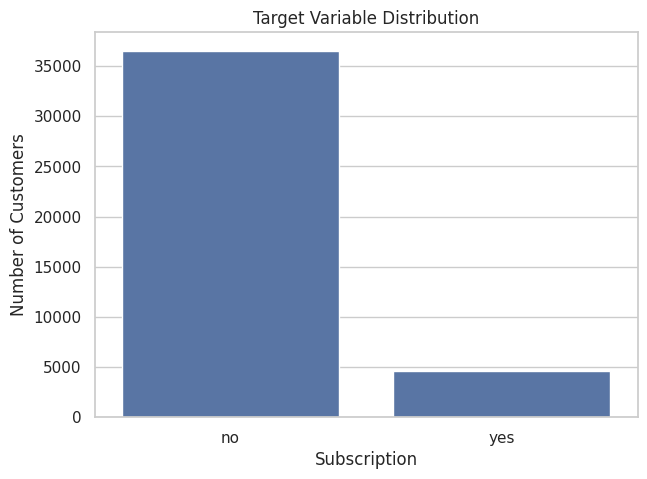

In [7]:
# 5.1 Target Variable Distribution

plt.figure(figsize=(7, 5))

sns.countplot(data=df, x='y')

plt.title('Target Variable Distribution')
plt.xlabel('Subscription')
plt.ylabel('Number of Customers')

plt.show()

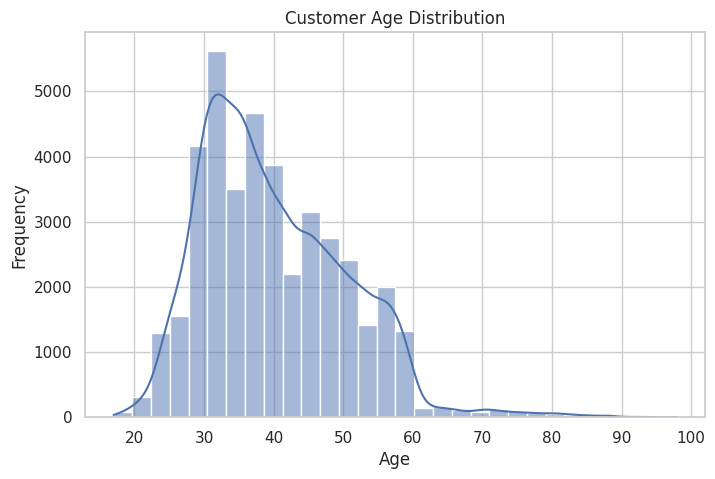

In [8]:
# 5.2 Customer Age Distribution

plt.figure(figsize=(8, 5))

sns.histplot(
    data=df,
    x='age',
    bins=30,
    kde=True
)

plt.title('Customer Age Distribution')
plt.xlabel('Age')
plt.ylabel('Frequency')

plt.show()

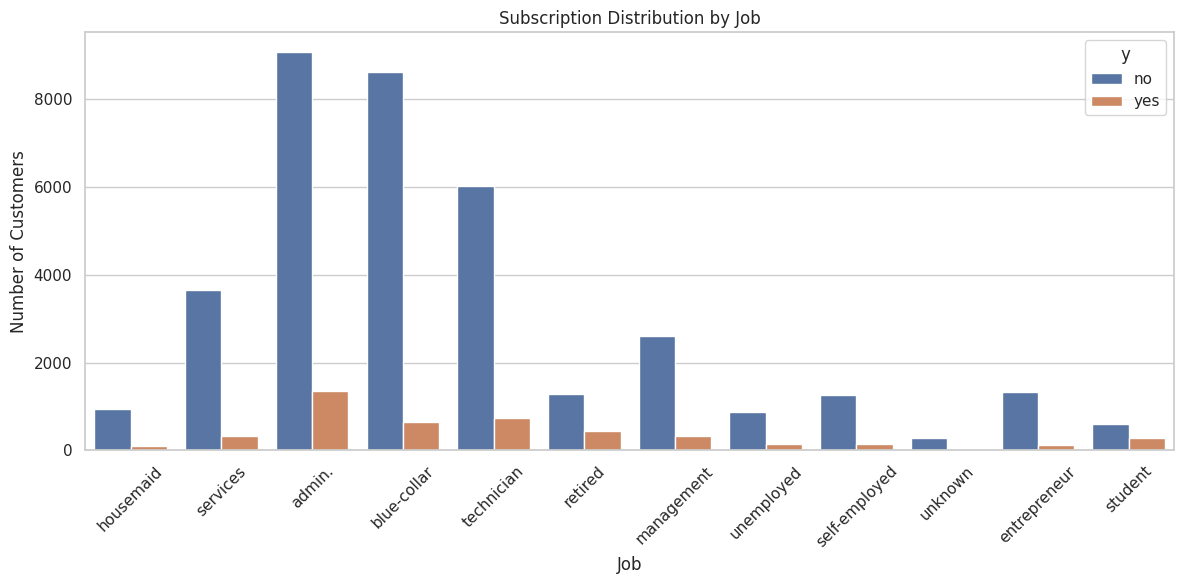

In [9]:
# 5.3 Subscription Distribution by Job

plt.figure(figsize=(12, 6))

sns.countplot(
    data=df,
    x='job',
    hue='y'
)

plt.title('Subscription Distribution by Job')
plt.xlabel('Job')
plt.ylabel('Number of Customers')

plt.xticks(rotation=45)

plt.tight_layout()
plt.show()

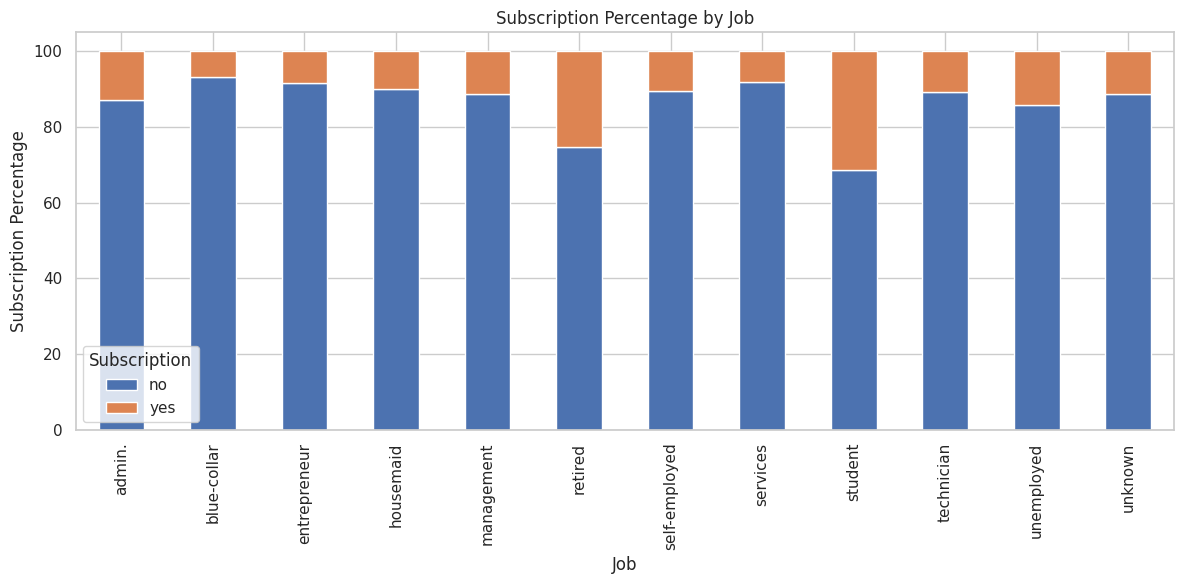

In [10]:
# 5.4 Subscription Percentage by Job

job_subscription = pd.crosstab(
    df['job'],
    df['y'],
    normalize='index'
) * 100

job_subscription.plot(
    kind='bar',
    stacked=True,
    figsize=(12, 6)
)

plt.title('Subscription Percentage by Job')
plt.xlabel('Job')
plt.ylabel('Subscription Percentage')

plt.legend(title='Subscription')

plt.tight_layout()
plt.show()

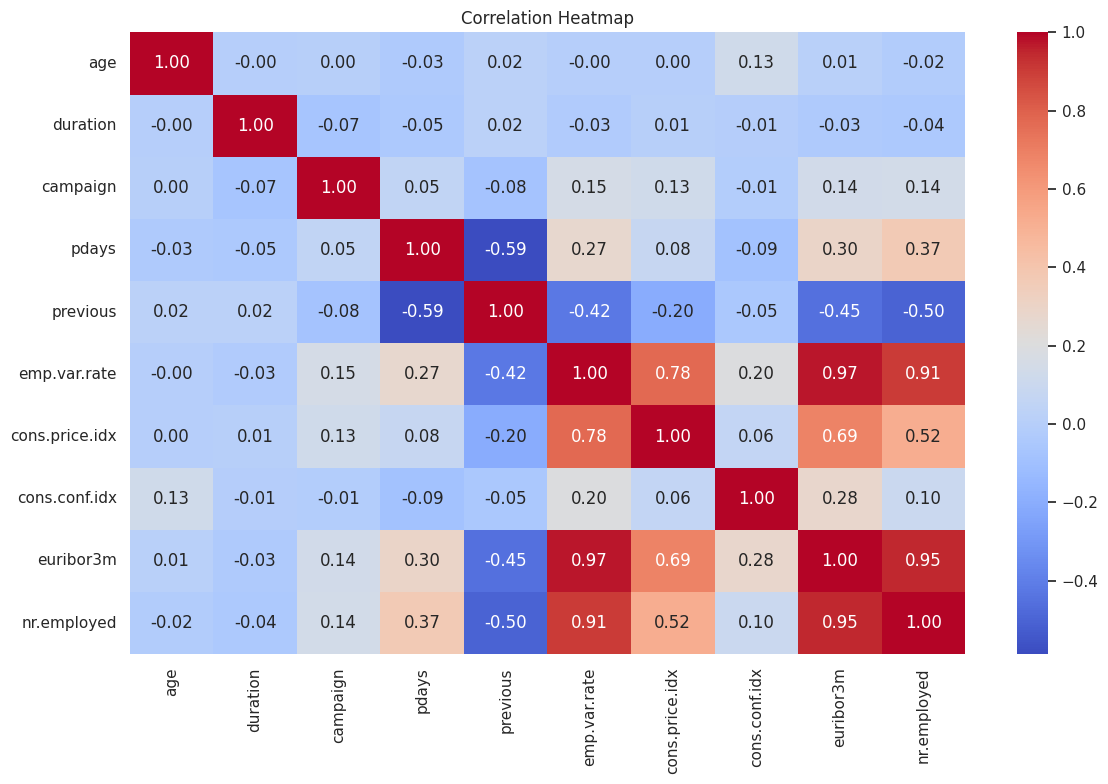

In [11]:
# 5.5 Correlation Heatmap

numerical_df = df.select_dtypes(
    include=['int64', 'float64']
)

plt.figure(figsize=(12, 8))

sns.heatmap(
    numerical_df.corr(),
    annot=True,
    cmap='coolwarm',
    fmt='.2f'
)

plt.title('Correlation Heatmap')

plt.tight_layout()
plt.show()

In [12]:
# 6. Data Cleaning

print("Duplicates before cleaning:", df.duplicated().sum())

# Remove duplicate records

df = df.drop_duplicates().reset_index(drop=True)

print("Duplicates after cleaning:", df.duplicated().sum())

print("Final Dataset Shape:", df.shape)

Duplicates before cleaning: 12
Duplicates after cleaning: 0
Final Dataset Shape: (41176, 21)



### 6.1 Data Cleaning Observations

1. Initially, the dataset contained 41,188 records.
2. A total of 12 duplicate records were identified.
3. The duplicate records were removed using the drop_duplicates() method.
4. After cleaning, the dataset contains 41,176 records.
5. No duplicate records remain after cleaning.
6. No conventional missing values were identified during dataset exploration.
7. Unknown categorical values are retained for further preprocessing.



## 7. Feature Selection and Target Separation

The target variable is 'y', which indicates whether a customer subscribed to a term deposit.

The remaining relevant columns are treated as independent variables.

The duration feature is excluded because it represents the duration of a completed call and is not available when predicting customer subscription before the call.

The target variable is encoded as:
- 0: No subscription
- 1: Yes subscription


In [13]:
# 7. Feature Selection and Target Separation

# Separate independent variables and target variable

X = df.drop(columns=['y', 'duration'])

y = df['y'].map({
    'no': 0,
    'yes': 1
})

# Display dataset dimensions

print("Independent Variables Shape:", X.shape)

print("Target Variable Shape:", y.shape)

# Display target distribution

print("\nTarget Distribution:")
print(y.value_counts())

# Check for missing target values

print("\nMissing Target Values:", y.isnull().sum())

Independent Variables Shape: (41176, 19)
Target Variable Shape: (41176,)

Target Distribution:
y
0    36537
1     4639
Name: count, dtype: int64

Missing Target Values: 0


## 8. Train-Test Split

The dataset is divided into 80% training data and 20% testing data.

Stratified sampling is used to maintain the original distribution of both target classes in the training and testing datasets.

A fixed random state of 42 ensures reproducibility.

In [14]:
# 8. Train-Test Split

from sklearn.model_selection import train_test_split

X_train, X_test, y_train, y_test = train_test_split(
    X,
    y,
    test_size=0.20,
    random_state=42,
    stratify=y
)

print("Training Features Shape:", X_train.shape)
print("Testing Features Shape:", X_test.shape)

print("\nTraining Target Distribution:")
print(y_train.value_counts(normalize=True) * 100)

print("\nTesting Target Distribution:")
print(y_test.value_counts(normalize=True) * 100)

Training Features Shape: (32940, 19)
Testing Features Shape: (8236, 19)

Training Target Distribution:
y
0    88.734062
1    11.265938
Name: proportion, dtype: float64

Testing Target Distribution:
y
0    88.732394
1    11.267606
Name: proportion, dtype: float64


## 9. Data Preprocessing

The dataset contains both numerical and categorical features.

The following preprocessing techniques are applied:

- StandardScaler: Standardizes numerical features.
- OneHotEncoder: Converts categorical features into numerical format.
- ColumnTransformer: Applies the appropriate transformation to each feature type.

The preprocessing is fitted only on the training dataset to prevent data leakage.

In [15]:
# 9. Data Preprocessing

from sklearn.compose import ColumnTransformer
from sklearn.preprocessing import StandardScaler, OneHotEncoder

# Identify numerical and categorical columns
numerical_features = X_train.select_dtypes(include=['int64', 'float64']).columns.tolist()

categorical_features = X_train.select_dtypes(include=['object']).columns.tolist()

print("Numerical Features:", numerical_features)
print("\nNumber of Numerical Features:", len(numerical_features))

print("\nCategorical Features:", categorical_features)
print("\nNumber of Categorical Features:", len(categorical_features))

# Create preprocessing transformer
preprocessor = ColumnTransformer(
    transformers=[
        ('num', StandardScaler(), numerical_features),
        ('cat', OneHotEncoder(handle_unknown='ignore', sparse_output=False), categorical_features)
    ]
)

print("\nPreprocessing pipeline created successfully.")

Numerical Features: ['age', 'campaign', 'pdays', 'previous', 'emp.var.rate', 'cons.price.idx', 'cons.conf.idx', 'euribor3m', 'nr.employed']

Number of Numerical Features: 9

Categorical Features: ['job', 'marital', 'education', 'default', 'housing', 'loan', 'contact', 'month', 'day_of_week', 'poutcome']

Number of Categorical Features: 10

Preprocessing pipeline created successfully.


## 10. Model 1 – Logistic Regression

Logistic Regression is a supervised classification algorithm used to predict the probability of a binary outcome.

In this project:
- 0 represents No subscription.
- 1 represents Yes subscription.

The class_weight='balanced' parameter is used to address class imbalance by assigning higher weights to the minority class.

The preprocessing and model training are combined using a Pipeline.

In [16]:
# 10. Model 1 – Logistic Regression

from sklearn.pipeline import Pipeline
from sklearn.linear_model import LogisticRegression

# Create Logistic Regression pipeline
lr_model = Pipeline(steps=[
    ('preprocessor', preprocessor),
    ('classifier', LogisticRegression(
        max_iter=1000,
        class_weight='balanced',
        random_state=42
    ))
])

# Train the model
lr_model.fit(X_train, y_train)

print("Logistic Regression model trained successfully!")

# Predict on test data
lr_predictions = lr_model.predict(X_test)

# Predict probabilities for AUC calculation
lr_probabilities = lr_model.predict_proba(X_test)[:, 1]

print("\nFirst 10 Predictions:", lr_predictions[:10])
print("First 10 Actual Values:", y_test.values[:10])

Logistic Regression model trained successfully!

First 10 Predictions: [0 1 0 0 0 0 0 0 0 0]
First 10 Actual Values: [0 1 0 0 0 0 0 0 0 0]


## 11. Evaluation of Logistic Regression

The Logistic Regression model is evaluated using six classification metrics:

1. Accuracy
2. AUC (Area Under the ROC Curve)
3. Precision
4. Recall
5. F1-score
6. Matthews Correlation Coefficient (MCC)

In [17]:
# 11. Evaluation of Logistic Regression

from sklearn.metrics import (
    accuracy_score,
    roc_auc_score,
    precision_score,
    recall_score,
    f1_score,
    matthews_corrcoef,
    confusion_matrix,
    classification_report
)

# Calculate evaluation metrics
lr_accuracy = accuracy_score(y_test, lr_predictions)
lr_auc = roc_auc_score(y_test, lr_probabilities)
lr_precision = precision_score(y_test, lr_predictions, zero_division=0)
lr_recall = recall_score(y_test, lr_predictions, zero_division=0)
lr_f1 = f1_score(y_test, lr_predictions, zero_division=0)
lr_mcc = matthews_corrcoef(y_test, lr_predictions)

print("Logistic Regression Evaluation")
print("--------------------------------")
print("Accuracy :", round(lr_accuracy, 4))
print("AUC      :", round(lr_auc, 4))
print("Precision:", round(lr_precision, 4))
print("Recall   :", round(lr_recall, 4))
print("F1 Score :", round(lr_f1, 4))
print("MCC      :", round(lr_mcc, 4))

print("\nConfusion Matrix:")
print(confusion_matrix(y_test, lr_predictions))

print("\nClassification Report:")
print(classification_report(y_test, lr_predictions, zero_division=0))

Logistic Regression Evaluation
--------------------------------
Accuracy : 0.8303
AUC      : 0.8002
Precision: 0.3591
Recall   : 0.6455
F1 Score : 0.4615
MCC      : 0.3928

Confusion Matrix:
[[6239 1069]
 [ 329  599]]

Classification Report:
              precision    recall  f1-score   support

           0       0.95      0.85      0.90      7308
           1       0.36      0.65      0.46       928

    accuracy                           0.83      8236
   macro avg       0.65      0.75      0.68      8236
weighted avg       0.88      0.83      0.85      8236



## 12. Model 2 – Decision Tree Classifier

A Decision Tree is a supervised machine learning algorithm that makes predictions by splitting data into branches based on feature values.

It can capture nonlinear relationships and does not require feature scaling. We retain the same preprocessing pipeline for consistency across models.

The class_weight='balanced' parameter is used to address class imbalance.

In [18]:
# 12. Model 2 – Decision Tree Classifier

from sklearn.tree import DecisionTreeClassifier
from sklearn.pipeline import Pipeline

# Create Decision Tree pipeline
dt_model = Pipeline(steps=[
    ('preprocessor', preprocessor),
    ('classifier', DecisionTreeClassifier(
        max_depth=10,
        class_weight='balanced',
        random_state=42
    ))
])

# Train the model
dt_model.fit(X_train, y_train)

print("Decision Tree model trained successfully!")

# Predict on test data
dt_predictions = dt_model.predict(X_test)

# Predict probabilities for AUC calculation
dt_probabilities = dt_model.predict_proba(X_test)[:, 1]

print("\nFirst 10 Predictions:", dt_predictions[:10])
print("First 10 Actual Values:", y_test.values[:10])

Decision Tree model trained successfully!

First 10 Predictions: [0 1 1 1 0 0 0 0 0 0]
First 10 Actual Values: [0 1 0 0 0 0 0 0 0 0]


## 13. Evaluation of Decision Tree

The Decision Tree model is evaluated using Accuracy, AUC, Precision, Recall, F1-score and Matthews Correlation Coefficient (MCC).

A confusion matrix and classification report are also generated to understand the model's prediction performance.

In [19]:
# 13. Evaluation of Decision Tree

dt_accuracy = accuracy_score(y_test, dt_predictions)
dt_auc = roc_auc_score(y_test, dt_probabilities)
dt_precision = precision_score(y_test, dt_predictions, zero_division=0)
dt_recall = recall_score(y_test, dt_predictions, zero_division=0)
dt_f1 = f1_score(y_test, dt_predictions, zero_division=0)
dt_mcc = matthews_corrcoef(y_test, dt_predictions)

print("Decision Tree Evaluation")
print("--------------------------------")
print("Accuracy :", round(dt_accuracy, 4))
print("AUC      :", round(dt_auc, 4))
print("Precision:", round(dt_precision, 4))
print("Recall   :", round(dt_recall, 4))
print("F1 Score :", round(dt_f1, 4))
print("MCC      :", round(dt_mcc, 4))

print("\nConfusion Matrix:")
print(confusion_matrix(y_test, dt_predictions))

print("\nClassification Report:")
print(classification_report(y_test, dt_predictions, zero_division=0))

Decision Tree Evaluation
--------------------------------
Accuracy : 0.8473
AUC      : 0.7693
Precision: 0.3859
Recall   : 0.6013
F1 Score : 0.4701
MCC      : 0.3987

Confusion Matrix:
[[6420  888]
 [ 370  558]]

Classification Report:
              precision    recall  f1-score   support

           0       0.95      0.88      0.91      7308
           1       0.39      0.60      0.47       928

    accuracy                           0.85      8236
   macro avg       0.67      0.74      0.69      8236
weighted avg       0.88      0.85      0.86      8236



## 14. Model 3 – K-Nearest Neighbors (KNN)

K-Nearest Neighbors is a supervised classification algorithm that predicts the class of a new data point based on the majority class among its nearest neighbors.

In this project, KNN uses 5 nearest neighbors. Numerical features are standardized because KNN relies on distance calculations.

In [20]:
# 14. Model 3 – K-Nearest Neighbors

from sklearn.neighbors import KNeighborsClassifier
from sklearn.pipeline import Pipeline

# Create KNN pipeline
knn_model = Pipeline(steps=[
    ('preprocessor', preprocessor),
    ('classifier', KNeighborsClassifier(n_neighbors=5))
])

# Train the model
knn_model.fit(X_train, y_train)

print("KNN model trained successfully!")

# Predict on test data
knn_predictions = knn_model.predict(X_test)

# Predict probabilities for AUC calculation
knn_probabilities = knn_model.predict_proba(X_test)[:, 1]

print("\nFirst 10 Predictions:", knn_predictions[:10])
print("First 10 Actual Values:", y_test.values[:10])

KNN model trained successfully!

First 10 Predictions: [0 1 0 0 0 0 0 0 0 0]
First 10 Actual Values: [0 1 0 0 0 0 0 0 0 0]


## 15. Evaluation of K-Nearest Neighbors (KNN)

The KNN model is evaluated using Accuracy, AUC, Precision, Recall, F1-score and Matthews Correlation Coefficient (MCC).

A confusion matrix and classification report are also generated.

In [21]:
# 15. Evaluation of KNN

knn_accuracy = accuracy_score(y_test, knn_predictions)
knn_auc = roc_auc_score(y_test, knn_probabilities)
knn_precision = precision_score(y_test, knn_predictions, zero_division=0)
knn_recall = recall_score(y_test, knn_predictions, zero_division=0)
knn_f1 = f1_score(y_test, knn_predictions, zero_division=0)
knn_mcc = matthews_corrcoef(y_test, knn_predictions)

print("KNN Evaluation")
print("--------------------------------")
print("Accuracy :", round(knn_accuracy, 4))
print("AUC      :", round(knn_auc, 4))
print("Precision:", round(knn_precision, 4))
print("Recall   :", round(knn_recall, 4))
print("F1 Score :", round(knn_f1, 4))
print("MCC      :", round(knn_mcc, 4))

print("\nConfusion Matrix:")
print(confusion_matrix(y_test, knn_predictions))

print("\nClassification Report:")
print(classification_report(y_test, knn_predictions, zero_division=0))

KNN Evaluation
--------------------------------
Accuracy : 0.8955
AUC      : 0.7404
Precision: 0.5661
Recall   : 0.3093
F1 Score : 0.4
MCC      : 0.3673

Confusion Matrix:
[[7088  220]
 [ 641  287]]

Classification Report:
              precision    recall  f1-score   support

           0       0.92      0.97      0.94      7308
           1       0.57      0.31      0.40       928

    accuracy                           0.90      8236
   macro avg       0.74      0.64      0.67      8236
weighted avg       0.88      0.90      0.88      8236



## 16. Model 4 – Gaussian Naive Bayes

Gaussian Naive Bayes is a probabilistic classification algorithm based on Bayes' theorem.

It assumes that numerical features follow a Gaussian (normal) distribution and that features are conditionally independent given the target class.

We use GaussianNB for this binary classification problem.

In [22]:
# 16. Model 4 – Gaussian Naive Bayes

from sklearn.naive_bayes import GaussianNB
from sklearn.pipeline import Pipeline

# Create Gaussian Naive Bayes pipeline
nb_model = Pipeline(steps=[
    ('preprocessor', preprocessor),
    ('classifier', GaussianNB())
])

# Train the model
nb_model.fit(X_train, y_train)

print("Gaussian Naive Bayes model trained successfully!")

# Predict on test data
nb_predictions = nb_model.predict(X_test)

# Predict probabilities for AUC calculation
nb_probabilities = nb_model.predict_proba(X_test)[:, 1]

print("\nFirst 10 Predictions:", nb_predictions[:10])
print("First 10 Actual Values:", y_test.values[:10])

Gaussian Naive Bayes model trained successfully!

First 10 Predictions: [0 1 1 0 0 0 0 0 0 0]
First 10 Actual Values: [0 1 0 0 0 0 0 0 0 0]


## 17. Evaluation of Gaussian Naive Bayes

The Gaussian Naive Bayes model is evaluated using Accuracy, AUC, Precision, Recall, F1-score and Matthews Correlation Coefficient (MCC).

A confusion matrix and classification report are also generated.

In [23]:
# 17. Evaluation of Gaussian Naive Bayes

nb_accuracy = accuracy_score(y_test, nb_predictions)
nb_auc = roc_auc_score(y_test, nb_probabilities)
nb_precision = precision_score(y_test, nb_predictions, zero_division=0)
nb_recall = recall_score(y_test, nb_predictions, zero_division=0)
nb_f1 = f1_score(y_test, nb_predictions, zero_division=0)
nb_mcc = matthews_corrcoef(y_test, nb_predictions)

print("Gaussian Naive Bayes Evaluation")
print("--------------------------------")
print("Accuracy :", round(nb_accuracy, 4))
print("AUC      :", round(nb_auc, 4))
print("Precision:", round(nb_precision, 4))
print("Recall   :", round(nb_recall, 4))
print("F1 Score :", round(nb_f1, 4))
print("MCC      :", round(nb_mcc, 4))

print("\nConfusion Matrix:")
print(confusion_matrix(y_test, nb_predictions))

print("\nClassification Report:")
print(classification_report(y_test, nb_predictions, zero_division=0))

Gaussian Naive Bayes Evaluation
--------------------------------
Accuracy : 0.8082
AUC      : 0.7761
Precision: 0.3199
Recall   : 0.6239
F1 Score : 0.4229
MCC      : 0.3478

Confusion Matrix:
[[6077 1231]
 [ 349  579]]

Classification Report:
              precision    recall  f1-score   support

           0       0.95      0.83      0.88      7308
           1       0.32      0.62      0.42       928

    accuracy                           0.81      8236
   macro avg       0.63      0.73      0.65      8236
weighted avg       0.88      0.81      0.83      8236



## 18. Model 5 – Random Forest Classifier

Random Forest is an ensemble machine learning algorithm that combines multiple decision trees to make predictions.

Each tree is trained using a different sample of the training data and a random subset of features.

The final prediction is determined by combining the predictions of individual trees.

In this project, we use 100 trees and class_weight='balanced' to address class imbalance.

In [24]:
# 18. Model 5 – Random Forest Classifier

from sklearn.ensemble import RandomForestClassifier
from sklearn.pipeline import Pipeline

# Create Random Forest pipeline
rf_model = Pipeline(steps=[
    ('preprocessor', preprocessor),
    ('classifier', RandomForestClassifier(
        n_estimators=100,
        max_depth=15,
        class_weight='balanced',
        random_state=42,
        n_jobs=-1
    ))
])

# Train the model
rf_model.fit(X_train, y_train)

print("Random Forest model trained successfully!")

# Predict on test data
rf_predictions = rf_model.predict(X_test)

# Predict probabilities for AUC calculation
rf_probabilities = rf_model.predict_proba(X_test)[:, 1]

print("\nFirst 10 Predictions:", rf_predictions[:10])
print("First 10 Actual Values:", y_test.values[:10])

Random Forest model trained successfully!

First 10 Predictions: [0 1 0 0 0 0 0 0 0 0]
First 10 Actual Values: [0 1 0 0 0 0 0 0 0 0]


## 19. Evaluation of Random Forest

The Random Forest model is evaluated using six classification metrics:

1. Accuracy
2. AUC
3. Precision
4. Recall
5. F1-score
6. Matthews Correlation Coefficient (MCC)

A confusion matrix and classification report are also generated.

In [25]:
# 19. Evaluation of Random Forest

rf_accuracy = accuracy_score(y_test, rf_predictions)
rf_auc = roc_auc_score(y_test, rf_probabilities)
rf_precision = precision_score(y_test, rf_predictions, zero_division=0)
rf_recall = recall_score(y_test, rf_predictions, zero_division=0)
rf_f1 = f1_score(y_test, rf_predictions, zero_division=0)
rf_mcc = matthews_corrcoef(y_test, rf_predictions)

print("Random Forest Evaluation")
print("--------------------------------")
print("Accuracy :", round(rf_accuracy, 4))
print("AUC      :", round(rf_auc, 4))
print("Precision:", round(rf_precision, 4))
print("Recall   :", round(rf_recall, 4))
print("F1 Score :", round(rf_f1, 4))
print("MCC      :", round(rf_mcc, 4))

print("\nConfusion Matrix:")
print(confusion_matrix(y_test, rf_predictions))

print("\nClassification Report:")
print(classification_report(y_test, rf_predictions, zero_division=0))

Random Forest Evaluation
--------------------------------
Accuracy : 0.8833
AUC      : 0.8085
Precision: 0.4841
Recall   : 0.5399
F1 Score : 0.5104
MCC      : 0.4453

Confusion Matrix:
[[6774  534]
 [ 427  501]]

Classification Report:
              precision    recall  f1-score   support

           0       0.94      0.93      0.93      7308
           1       0.48      0.54      0.51       928

    accuracy                           0.88      8236
   macro avg       0.71      0.73      0.72      8236
weighted avg       0.89      0.88      0.89      8236



## 20. Performance Comparison of All Five Models

All five classification algorithms are compared using the same test dataset and six evaluation metrics.

The comparison helps identify the most suitable model for predicting bank term deposit subscriptions.

In [26]:
# 20. Performance Comparison of All Five Models

import pandas as pd

comparison_data = {
    'Model': [
        'Logistic Regression',
        'Decision Tree',
        'KNN',
        'Gaussian Naive Bayes',
        'Random Forest'
    ],
    'Accuracy': [
        lr_accuracy, dt_accuracy, knn_accuracy, nb_accuracy, rf_accuracy
    ],
    'AUC': [
        lr_auc, dt_auc, knn_auc, nb_auc, rf_auc
    ],
    'Precision': [
        lr_precision, dt_precision, knn_precision, nb_precision, rf_precision
    ],
    'Recall': [
        lr_recall, dt_recall, knn_recall, nb_recall, rf_recall
    ],
    'F1 Score': [
        lr_f1, dt_f1, knn_f1, nb_f1, rf_f1
    ],
    'MCC': [
        lr_mcc, dt_mcc, knn_mcc, nb_mcc, rf_mcc
    ]
}

comparison_df = pd.DataFrame(comparison_data)

print("Final Model Comparison")
display(comparison_df.round(4))

Final Model Comparison


,Model,Accuracy,AUC,Precision,Recall,F1 Score,MCC
0,Logistic Regression,0.8303,0.8002,0.3591,0.6455,0.4615,0.3928
1,Decision Tree,0.8473,0.7693,0.3859,0.6013,0.4701,0.3987
2,KNN,0.8955,0.7404,0.5661,0.3093,0.4000,0.3673
3,Gaussian Naive Bayes,0.8082,0.7761,0.3199,0.6239,0.4229,0.3478
4,Random Forest,0.8833,0.8085,0.4841,0.5399,0.5104,0.4453


## 21. Model Performance Visualization

Bar charts are generated to compare the performance of all five classification models using the six evaluation metrics.

These visualizations help identify the strengths and weaknesses of each algorithm.

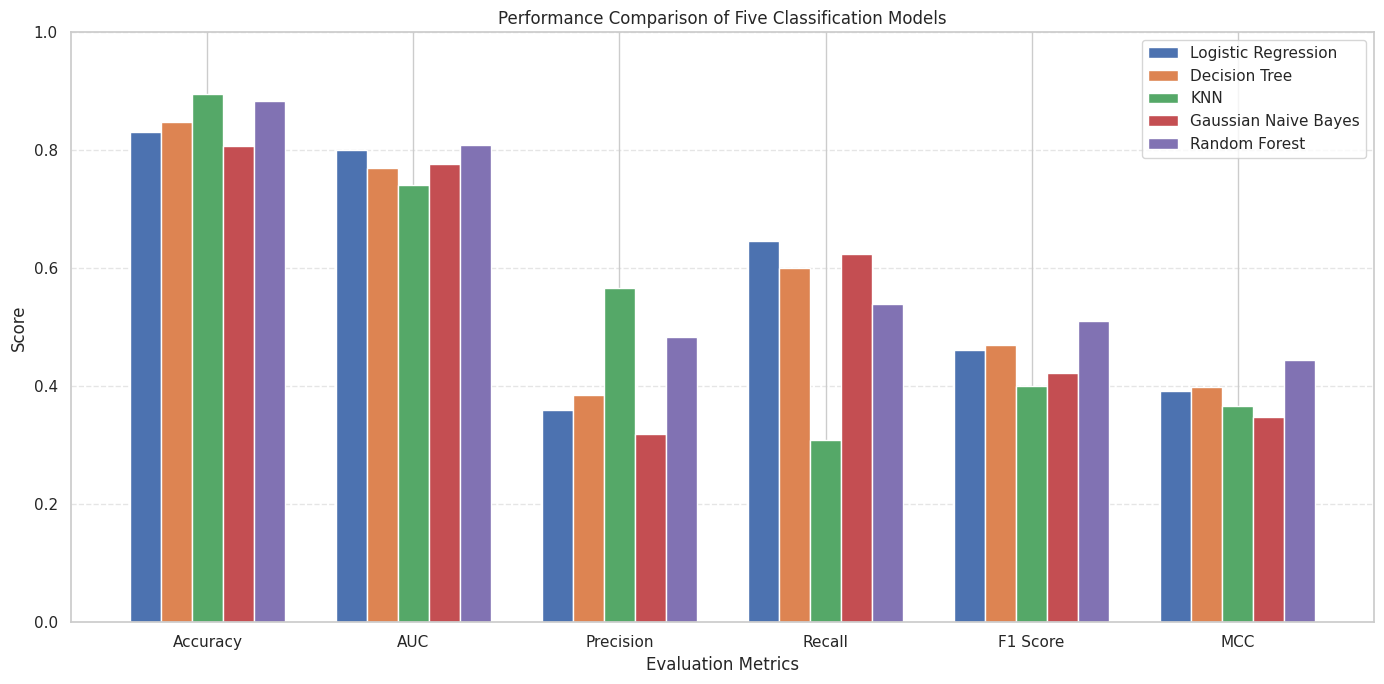

In [27]:
# 21. Model Performance Visualization

import matplotlib.pyplot as plt
import numpy as np

metrics = ['Accuracy', 'AUC', 'Precision', 'Recall', 'F1 Score', 'MCC']

x = np.arange(len(metrics))
width = 0.15

plt.figure(figsize=(14, 7))

for i, row in comparison_df.iterrows():
    values = [row[metric] for metric in metrics]

    plt.bar(
        x + (i - 2) * width,
        values,
        width,
        label=row['Model']
    )

plt.xlabel('Evaluation Metrics')
plt.ylabel('Score')
plt.title('Performance Comparison of Five Classification Models')
plt.xticks(x, metrics)
plt.ylim(0, 1)
plt.legend(loc='upper right')
plt.grid(axis='y', linestyle='--', alpha=0.5)

plt.tight_layout()
plt.show()

## 22. Individual Metric Comparison

Individual bar charts are generated for each evaluation metric to provide a clearer comparison of the five classification algorithms.

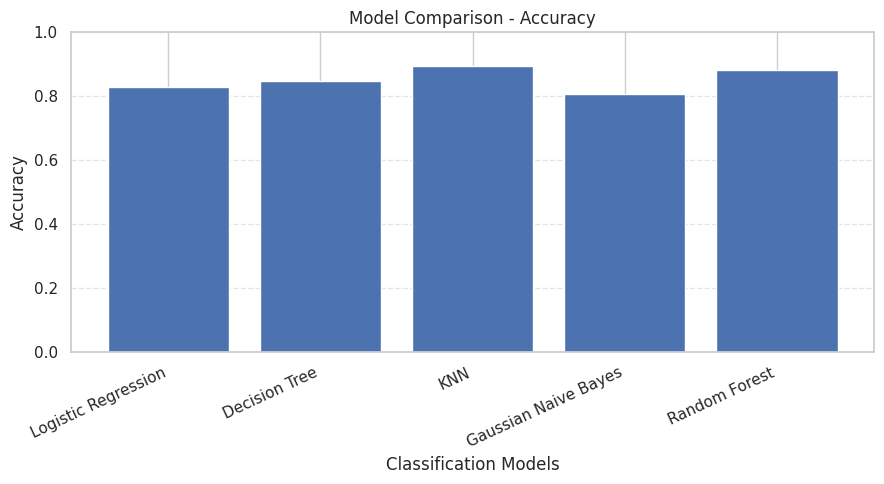

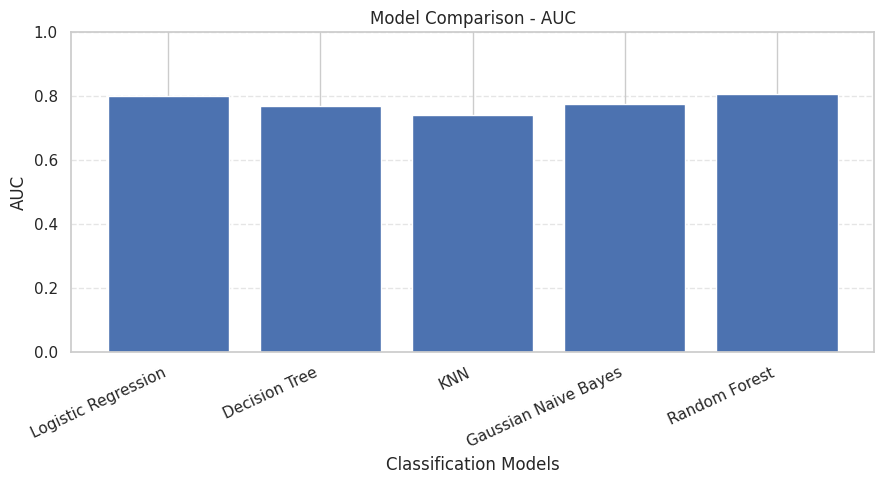

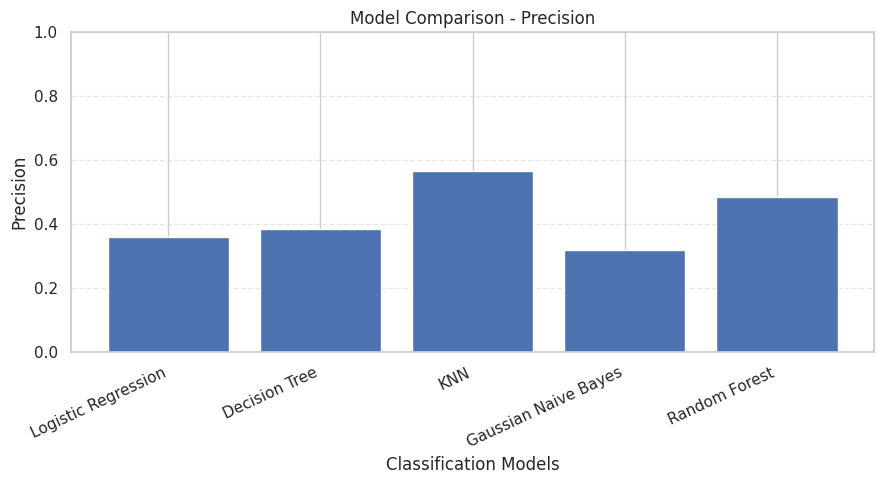

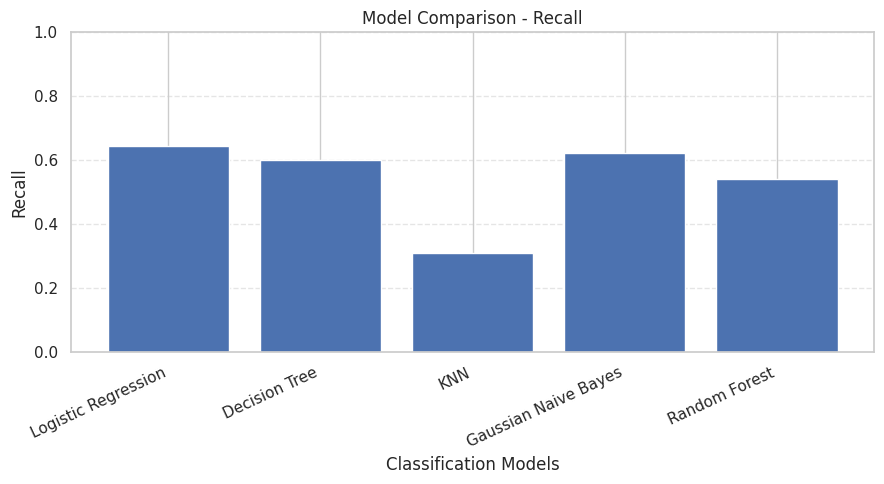

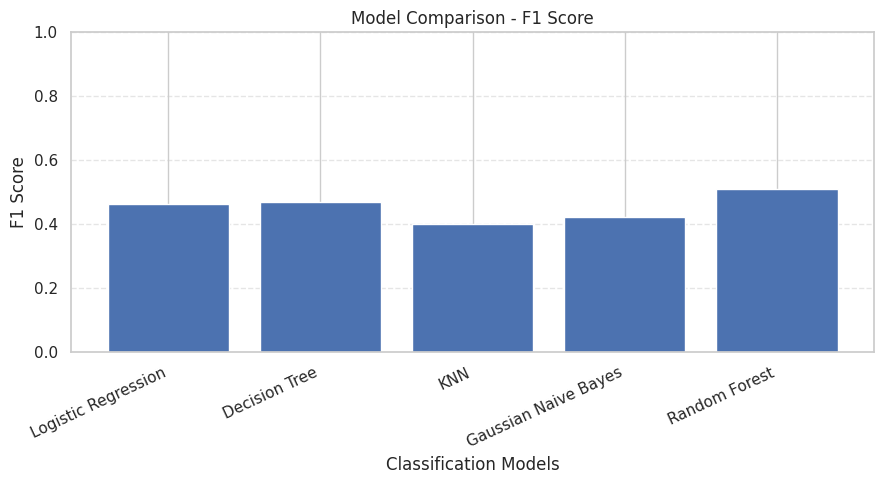

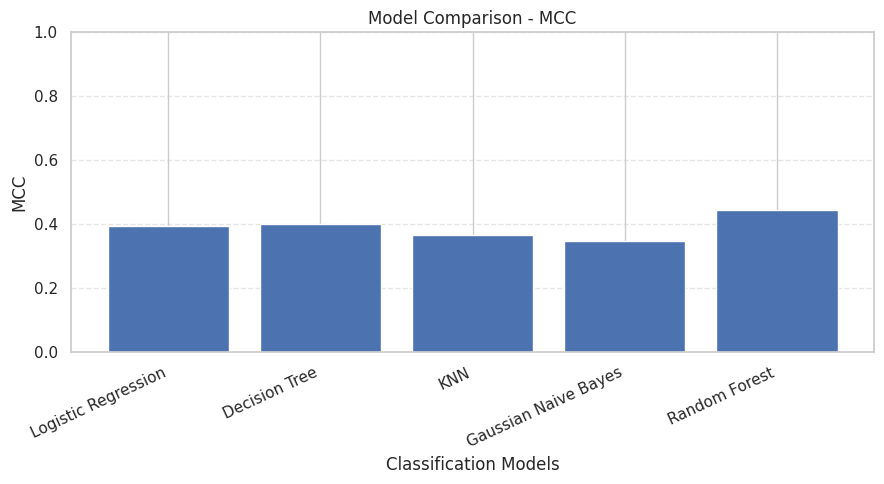

In [31]:
# 22. Individual Metric Comparison

metrics = ['Accuracy', 'AUC', 'Precision', 'Recall', 'F1 Score', 'MCC']

for metric in metrics:
    plt.figure(figsize=(9, 5))

    plt.bar(comparison_df['Model'], comparison_df[metric])

    plt.title(f'Model Comparison - {metric}')
    plt.xlabel('Classification Models')
    plt.ylabel(metric)
    plt.ylim(0, 1)
    plt.xticks(rotation=25, ha='right')
    plt.grid(axis='y', linestyle='--', alpha=0.5)

    plt.tight_layout()
    plt.show()

## 23. Model-wise Observations

### 1. Logistic Regression
- Achieved an accuracy of 83.03% and an AUC of 0.8002.
- Obtained the highest recall of 64.55%, identifying the largest proportion of actual subscribers.
- Demonstrated reasonable classification performance but relatively low precision.

### 2. Decision Tree
- Achieved an accuracy of 84.73%.
- Obtained an F1-score of 0.4701.
- Provided a balance between precision and recall, but its AUC was lower than Logistic Regression and Random Forest.

### 3. K-Nearest Neighbors (KNN)
- Achieved the highest accuracy of 89.55% and the highest precision of 56.61%.
- However, its recall was only 30.93%.
- It performed well in identifying non-subscribers but missed many actual subscribers.

### 4. Gaussian Naive Bayes
- Achieved an accuracy of 80.82%.
- Obtained a recall of 62.39%.
- It identified a reasonable proportion of subscribers but had relatively low precision and MCC.

### 5. Random Forest
- Achieved an accuracy of 88.33% and the highest AUC of 0.8085.
- Obtained the highest F1-score of 0.5104 and MCC of 0.4453.
- Demonstrated the best overall balance between precision and recall among the five models.

## 24. Overall Conclusion

In this project, five supervised machine learning classification algorithms were implemented to predict whether a bank customer would subscribe to a term deposit.

The Bank Marketing dataset was preprocessed using duplicate removal, categorical encoding and numerical feature scaling. The dataset was divided into training and testing sets using an 80:20 stratified split.

The five models were evaluated using Accuracy, AUC, Precision, Recall, F1-score and Matthews Correlation Coefficient.

Based on the evaluation results, Random Forest was selected as the best overall model. It achieved the highest AUC (0.8085), F1-score (0.5104) and MCC (0.4453).

Although KNN achieved the highest accuracy (89.55%), its low recall (30.93%) indicated that it missed many actual subscribers.

Therefore, Random Forest provides the most balanced performance among the five evaluated models for this classification problem.

This experiment demonstrates why multiple evaluation metrics are important, particularly when working with imbalanced classification datasets.

## 25. Saving Trained Models

All five trained machine learning pipelines are saved using Joblib.

Each saved pipeline includes both the preprocessing transformations and the trained classifier, allowing predictions on new data using the same preprocessing steps.

In [32]:
# 25. Save all five trained models

import joblib
import os

os.makedirs('models', exist_ok=True)

joblib.dump(lr_model, 'models/logistic_regression.pkl')
joblib.dump(dt_model, 'models/decision_tree.pkl')
joblib.dump(knn_model, 'models/knn.pkl')
joblib.dump(nb_model, 'models/gaussian_naive_bayes.pkl')
joblib.dump(rf_model, 'models/random_forest.pkl')

print("All five models saved successfully!")

print("\nSaved model files:")
print(os.listdir('models'))

All five models saved successfully!

Saved model files:
['decision_tree.pkl', 'random_forest.pkl', 'logistic_regression.pkl', 'gaussian_naive_bayes.pkl', 'knn.pkl']


## 26. Saving Test Dataset

The test dataset is exported as a CSV file containing the independent variables and actual target values.

This dataset can be used for model testing and reproducibility.

In [33]:
# 26. Save Test Dataset

test_data = X_test.copy()

test_data['y'] = y_test

test_data.to_csv('test_data.csv', index=False)

print("Test dataset saved successfully!")
print("Test dataset shape:", test_data.shape)
print("File name: test_data.csv")

Test dataset saved successfully!
Test dataset shape: (8236, 20)
File name: test_data.csv


## 27. Project Dependencies

The following Python libraries are required to execute this project.

In [34]:
# 27. Create requirements.txt

requirements = """pandas
numpy
scikit-learn
matplotlib
seaborn
joblib
"""

with open('requirements.txt', 'w') as file:
    file.write(requirements)

print("requirements.txt created successfully!")

requirements.txt created successfully!


In [35]:
# Check requirements.txt

with open('requirements.txt', 'r') as file:
    print(file.read())

pandas
numpy
scikit-learn
matplotlib
seaborn
joblib



In [36]:
from google.colab import files
files.download('requirements.txt')

<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>

In [37]:
from google.colab import files
files.download('test_data.csv')

<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>